# 1. Carga y descripción inicial de los datos

El conjunto de datos utilizado contiene información sobre los nacidos vivos registrados en la República Argentina entre los años 2005 y 2022.

En esta primera etapa se carga el archivo y se realiza una inspección inicial para conocer sus dimensiones, las variables disponibles y la estructura de los registros. También se observan las primeras filas para familiarizarse con el formato y el contenido de los datos.

Esta revisión se realiza antes de aplicar filtros, eliminar registros o modificar variables. De esta manera, se obtiene una primera aproximación a la información disponible y se establece un punto de partida para el análisis exploratorio y la posterior preparación de los datos para el modelado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import os

from pathlib import Path
import zipfile

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")

In [2]:
ruta_datos = Path("../data/raw/nacimientos_argentina_2005_2022.zip")

df = pd.read_csv(ruta_datos, compression="zip")

print("Dimensiones del dataset original:", df.shape)

display(df.head())

Dimensiones del dataset original: (546963, 12)


,anio,jurisdiccion_de_residencia_id,jurisdicion_residencia_nombre,edad_madre_grupo,instruccion_madre,tipo_de_parto_id,tipo_de_parto_nombre,semana_gestacion,intervalo_peso_al_nacer,sexo_id,Sexo,nacimientos_cantidad
0,2005,2,Ciudad Autónoma de Buenos Aires,5.30 a 34,3.Primaria/C. EGB Completa,1.0,Simple,4.28 a 31,2.500 a 999,1,masculino,2
1,2022,6,Buenos Aires,3.20 a 24,4.Secundaria/Polimodal Incompleta,1.0,Simple,1.Menos de 22,2.500 a 999,1,masculino,1
2,2005,2,Ciudad Autónoma de Buenos Aires,5.30 a 34,3.Primaria/C. EGB Completa,1.0,Simple,3.24 a 27,2.500 a 999,1,masculino,2
3,2022,6,Buenos Aires,3.20 a 24,4.Secundaria/Polimodal Incompleta,1.0,Simple,3.24 a 27,4.1500 a 1999,1,masculino,2
4,2005,2,Ciudad Autónoma de Buenos Aires,5.30 a 34,3.Primaria/C. EGB Completa,1.0,Simple,2.22 a 23,2.500 a 999,1,masculino,1


## 2. Preparación del conjunto de datos

Se crea una copia del dataset original denominada `df_eda`, que se utilizará para realizar las tareas de limpieza y preparación.

Esta decisión permite conservar los datos originales sin modificaciones y trabajar sobre una versión independiente destinada al análisis exploratorio.

### 2.1. Tratamiento de registros sin peso al nacer especificado

Se identifican y excluyen los registros cuya categoría de peso al nacer corresponde a "Sin especificar".

Esta decisión se debe a que el peso al nacer es la variable utilizada para construir la clase objetivo `bajo_peso`. Cuando este dato no está informado, no es posible determinar si el nacimiento corresponde a la categoría de bajo peso o sin bajo peso.

Por este motivo, estos registros se excluyen del conjunto de datos destinado al análisis de clasificación.

Se contabilizan tanto los registros excluidos como la cantidad de nacimientos que representan, utilizando la variable `nacimientos_cantidad`.

In [3]:
df_eda = df.copy()

mascara_peso_sin_especificar = (
    df_eda["intervalo_peso_al_nacer"] == "9.Sin especificar"
)

registros_excluidos = mascara_peso_sin_especificar.sum()

nacimientos_excluidos = df_eda.loc[
    mascara_peso_sin_especificar,
    "nacimientos_cantidad"
].sum()

df_eda = df_eda.loc[
    ~mascara_peso_sin_especificar
].copy()

print("Registros originales:", len(df))
print("Registros excluidos:", registros_excluidos)
print("Nacimientos excluidos:", nacimientos_excluidos)
print("Registros disponibles para el análisis:", len(df_eda))

Registros originales: 546963
Registros excluidos: 26432
Nacimientos excluidos: 145857
Registros disponibles para el análisis: 520531


In [4]:
print(
    "Duplicados después de excluir pesos sin especificar:",
    df_eda.duplicated().sum()
)

Duplicados después de excluir pesos sin especificar: 0


### 2.2. Inspección de la estructura del dataset

Se revisa la estructura del conjunto de datos mediante sus tipos de variables y la cantidad de valores no nulos de cada columna. Esta inspección permite identificar posibles problemas de calidad que requieren tratamiento antes del análisis.

In [5]:
print("Información del dataset:")
df_eda.info()

Información del dataset:
<class 'pandas.DataFrame'>
Index: 520531 entries, 0 to 546961
Data columns (total 12 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   anio                           520531 non-null  int64  
 1   jurisdiccion_de_residencia_id  520531 non-null  int64  
 2   jurisdicion_residencia_nombre  517825 non-null  str    
 3   edad_madre_grupo               520531 non-null  str    
 4   instruccion_madre              520531 non-null  str    
 5   tipo_de_parto_id               520531 non-null  float64
 6   tipo_de_parto_nombre           520531 non-null  str    
 7   semana_gestacion               520531 non-null  str    
 8   intervalo_peso_al_nacer        520531 non-null  str    
 9   sexo_id                        520531 non-null  int64  
 10  Sexo                           520531 non-null  str    
 11  nacimientos_cantidad           520531 non-null  int64  
dtypes: float64(1), int64(

### 2.3. Normalización de la variable de jurisdicción

Se inspeccionan los códigos y nombres de las jurisdicciones para identificar las categorías presentes y contrastarlas con el diccionario de datos.

Se detectan valores faltantes en el nombre de la jurisdicción asociados al código 98, correspondiente a "Otro país". Por este motivo, se completa esa información utilizando la categoría correspondiente.

También se normaliza la etiqueta "Sin Información" como "Lugar no especificado", manteniendo la distinción entre ambas categorías.

In [6]:
display(
    df_eda[
        ["jurisdiccion_de_residencia_id", "jurisdicion_residencia_nombre"]
    ]
    .drop_duplicates()
    .sort_values("jurisdiccion_de_residencia_id")
    .tail(15)
)

,jurisdiccion_de_residencia_id,jurisdicion_residencia_nombre
1493,46,La Rioja
176,50,Mendoza
173,54,Misiones
126,58,Neuquén
1838,62,Río Negro
2317,66,Salta
172,70,San Juan
292,74,San Luis
123,78,Santa Cruz
174,82,Santa Fe


In [7]:
df_eda["jurisdicion_residencia_nombre"] = (
    df_eda["jurisdicion_residencia_nombre"]
    .fillna("Otro país")
    .replace("Sin Información", "Lugar no especificado")
)

In [8]:
print(
    "Valores faltantes:",
    df_eda["jurisdicion_residencia_nombre"].isna().sum()
)

display(
    df_eda["jurisdicion_residencia_nombre"].value_counts()
)

Valores faltantes: 0


jurisdicion_residencia_nombre
Buenos Aires                                             67257
Santa Fe                                                 30765
Córdoba                                                  30376
Ciudad Autónoma de Buenos Aires                          28769
Tucumán                                                  27258
Misiones                                                 26022
Chaco                                                    25952
Corrientes                                               25782
Salta                                                    24877
Entre Ríos                                               22536
Mendoza                                                  21834
Santiago del Estero                                      20324
Formosa                                                  16745
Río Negro                                                15920
Jujuy                                                    15747
San Juan                 

In [9]:
print(
    "Duplicados después de las transformaciones:",
    df_eda.duplicated().sum()
)

Duplicados después de las transformaciones: 0


### 2.4. Normalización de la variable sexo

Se inspeccionan los valores presentes en la variable `Sexo` y su correspondencia con los códigos de `sexo_id`, contrastándolos con el diccionario de datos.

Se identifican cuatro categorías originales: masculino, femenino, desconocido e indeterminado.

Para adecuar la variable a las categorías utilizadas en el análisis, se unifican los registros de sexo desconocido e indeterminado bajo la categoría "Sin especificar", correspondiente al código 9.

Además, se normalizan las etiquetas de las categorías restantes como "Varón" y "Mujer".

De esta manera, la variable queda organizada en tres categorías: Varón, Mujer y Sin especificar.

Como consecuencia de esta unificación, algunos registros quedaron con características idénticas. Para evitar duplicaciones, se agruparon las filas coincidentes, sumando sus valores de `nacimientos_cantidad`. Este procedimiento redujo el conjunto de 520.531 a 520.422 registros, conservando el total de 12.311.460 nacimientos.

In [10]:
print("Valores faltantes:", df_eda["Sexo"].isna().sum())

display(
    df_eda["Sexo"]
    .value_counts(dropna=False)
    .to_frame(name="registros")
)

Valores faltantes: 0


,registros
Sexo,
masculino,260857
femenino,255260
desconocido,3639
indeterminado,775


In [11]:
display(
    df_eda[["sexo_id", "Sexo"]]
    .drop_duplicates()
    .sort_values("sexo_id")
)

,sexo_id,Sexo
0,1,masculino
4558,2,femenino
99274,3,indeterminado
100611,9,desconocido


In [12]:
df_eda["sexo_id"] = df_eda["sexo_id"].replace(3, 9)

df_eda["Sexo"] = df_eda["Sexo"].replace({
    "masculino": "Varón",
    "femenino": "Mujer",
    "desconocido": "Sin especificar",
    "indeterminado": "Sin especificar"
})

### 2.4.1 Agrupación de registros después de normalizar sexo

Luego de unificar las categorías "indeterminado" y "desconocido" bajo "Sin especificar", algunos registros presentan características idénticas.

Para evitar duplicados, se agrupan los registros con iguales características, sumando la cantidad de nacimientos que representan.

In [13]:
columnas_agrupacion = [
    columna
    for columna in df_eda.columns
    if columna != "nacimientos_cantidad"
]

df_eda = (
    df_eda
    .groupby(columnas_agrupacion, as_index=False, dropna=False)
    ["nacimientos_cantidad"]
    .sum()
)

In [14]:
print("Registros duplicados:", df_eda.duplicated().sum())
print("Cantidad de registros:", len(df_eda))
print(
    "Total de nacimientos:",
    df_eda["nacimientos_cantidad"].sum()
)

Registros duplicados: 0
Cantidad de registros: 520422
Total de nacimientos: 12311460


### 2.5. Normalización de la variable tipo de parto

Se inspeccionan los valores presentes en las variables `tipo_de_parto_id` y `tipo_de_parto_nombre`, y se verifica su correspondencia con el diccionario de datos.

Se identifican tres categorías: Simple (código 1), Múltiple (código 2) y Desconocido (código 9). No se detectan valores faltantes ni códigos adicionales.

Dado que las categorías coinciden con las definidas en el diccionario, no es necesario excluir ni agrupar registros. Únicamente se normalizan las etiquetas para mantener la consistencia con la nomenclatura del diccionario:

- `1`: Simple.
- `2`: Múltiple.
- `9`: Sin especificar.

Esta variable identifica si el nacimiento corresponde a un parto simple o múltiple; no indica la vía de parto (vaginal o cesárea).

In [15]:
print(
    "Valores faltantes:",
    df_eda["tipo_de_parto_nombre"].isna().sum()
)

display(
    df_eda["tipo_de_parto_nombre"]
    .value_counts(dropna=False)
    .to_frame(name="registros")
)

Valores faltantes: 0


,registros
tipo_de_parto_nombre,
Simple,425497
Multiple,89812
Desconocido,5113


In [16]:
display(
    df_eda[["tipo_de_parto_id", "tipo_de_parto_nombre"]]
    .drop_duplicates()
    .sort_values("tipo_de_parto_id")
)

,tipo_de_parto_id,tipo_de_parto_nombre
0,1.0,Simple
85,2.0,Multiple
637,9.0,Desconocido


In [17]:
df_eda["tipo_de_parto_nombre"] = df_eda["tipo_de_parto_nombre"].replace({
    "Multiple": "Múltiple",
    "Desconocido": "Sin especificar"
})

In [18]:
display(
    df_eda[["tipo_de_parto_id", "tipo_de_parto_nombre"]]
    .drop_duplicates()
    .sort_values("tipo_de_parto_id")
)

,tipo_de_parto_id,tipo_de_parto_nombre
0,1.0,Simple
85,2.0,Múltiple
637,9.0,Sin especificar


In [19]:
print(
    "Duplicados después de las transformaciones:",
    df_eda.duplicated().sum()
)

Duplicados después de las transformaciones: 0


### 2.6. Revisión de las variables categóricas restantes

Se inspeccionan las variables correspondientes al intervalo de edad materna, el tiempo de gestación, el nivel de instrucción de la madre y el intervalo de peso al nacer.

Para cada variable se comprueba la presencia de valores faltantes y se identifican las categorías existentes mediante sus frecuencias. Los valores observados se contrastan con la información disponible en el diccionario de datos.

Se identifican categorías como "Sin especificar", que representan información no consignada en el registro. Estas categorías se conservan como valores propios de las variables, ya que no se dispone de información suficiente para determinar el valor que correspondería a cada caso ni de criterios documentados para realizar una imputación.

Por lo tanto, se distingue entre los valores faltantes propiamente dichos y las categorías que indican información no especificada. No se consideran equivalentes a cero ni se eliminan automáticamente.

Esta revisión permite evaluar la consistencia de las variables antes de comenzar el análisis exploratorio gráfico.

In [20]:
variables_a_revisar = [
    "edad_madre_grupo",
    "semana_gestacion",
    "instruccion_madre",
    "intervalo_peso_al_nacer"
]

for variable in variables_a_revisar:
    print(f"\nVariable: {variable}")
    print("Valores faltantes:", df_eda[variable].isna().sum())

    display(
        df_eda[variable]
        .value_counts(dropna=False)
        .to_frame(name="registros")
    )


Variable: edad_madre_grupo
Valores faltantes: 0


,registros
edad_madre_grupo,
4.25 a 29,97124
5.30 a 34,94323
3.20 a 24,93071
6.35 a 39,79615
2.15 a 19,69227
7.40 a 44,47566
9.Sin especificar,13509
1.Menor de 15,13462
8.De 45 y más,12525



Variable: semana_gestacion
Valores faltantes: 0


,registros
semana_gestacion,
6.37 a 41,217635
5.32 a 36,164823
4.28 a 31,44882
8.Sin especificar,39022
7.42 y más,28418
3.24 a 27,19371
2.22 a 23,4554
1.Menos de 22,1717



Variable: instruccion_madre
Valores faltantes: 0


,registros
instruccion_madre,
5.Secundaria/Polimodal Completa,98939
3.Primaria/C. EGB Completa,95521
4.Secundaria/Polimodal Incompleta,94256
7.Terciaria/Universitaria Completa,65271
2.Primaria/C. EGB Incompleta,57468
6.Terciaria/Universitaria Incompleta,54063
8.Sin especificar,38086
1.Sin instrucción,16818



Variable: intervalo_peso_al_nacer
Valores faltantes: 0


,registros
intervalo_peso_al_nacer,
6.2500 a 2999,109327
7.3000 a 3499,103367
5.2000 a 2499,89196
8.De 3500 y más,87815
4.1500 a 1999,59026
3.1000 a 1499,41334
2.500 a 999,27115
1.Menor de 500,3242


### 2.7. Validación de la cantidad de nacimientos

Se verifica la integridad de la variable `nacimientos_cantidad`, que representa la cantidad de nacidos vivos correspondiente a cada registro del dataset.

Se comprueba la presencia de valores faltantes y de cantidades menores o iguales a cero. Además, se calculan estadísticas descriptivas para conocer la distribución de las cantidades de nacimientos representadas por los registros.

No se detectan valores faltantes ni cantidades menores o iguales a cero. Se observa que las cantidades representadas por cada registro presentan una distribución variable, por lo que una fila no equivale necesariamente a un nacimiento individual.

Esta variable se conserva y se utiliza como frecuencia o ponderación en los análisis exploratorios, de manera que los resultados representen la cantidad de nacimientos y no únicamente el número de registros.

Los valores no especificados de las demás variables se mantienen como categorías diferenciadas, sin asignarles valores que no estén respaldados por la información disponible.

In [21]:
print(
    "Valores faltantes:",
    df_eda["nacimientos_cantidad"].isna().sum()
)

print(
    "Valores menores o iguales a cero:",
    (df_eda["nacimientos_cantidad"] <= 0).sum()
)

display(
    df_eda["nacimientos_cantidad"].describe()
)

Valores faltantes: 0
Valores menores o iguales a cero: 0


count    520422.000000
mean         23.656686
std         133.289048
min           1.000000
25%           1.000000
50%           2.000000
75%           7.000000
max        4944.000000
Name: nacimientos_cantidad, dtype: float64

In [22]:
print(
    "Duplicados después de las transformaciones:",
    df_eda.duplicated().sum()
)

Duplicados después de las transformaciones: 0


## 3. Análisis Exploratorio de Datos (EDA)

### 3.1. Creación de la variable objetivo

Se crea la variable objetivo `bajo_peso` a partir de la variable `intervalo_peso_al_nacer`, utilizando como criterio el umbral de 2500 gramos.

De acuerdo con la definición adoptada para el proyecto, los nacimientos con un peso inferior a 2500 gramos se clasifican como bajo peso (valor 1), mientras que aquellos con un peso igual o superior a 2500 gramos se clasifican como sin bajo peso (valor 0).

Esta transformación permite convertir los intervalos originales de peso en una variable binaria, que será utilizada posteriormente para el análisis exploratorio y la clasificación retrospectiva.

La variable original `intervalo_peso_al_nacer` se conserva para mantener la información de origen, aunque no deberá utilizarse como variable predictora durante el modelado, ya que contiene la información empleada para construir la clase objetivo.

In [23]:
df_eda["bajo_peso"] = (
    df_eda["intervalo_peso_al_nacer"]
    .str.startswith(("1.", "2.", "3.", "4.", "5."))
    .astype(int)
)

### 3.2. Distribución de la variable objetivo

Se analiza la distribución de los nacimientos según la condición de bajo peso, con el objetivo de conocer la proporción de cada clase y evaluar el posible desequilibrio de la variable objetivo.

Para este análisis se utiliza la variable `nacimientos_cantidad` como ponderador, debido a que cada fila del dataset representa un registro agregado y no necesariamente un nacimiento individual.

Se calculan las cantidades totales y los porcentajes correspondientes a cada categoría:

- Sin bajo peso (0): peso igual o superior a 2500 gramos.
- Bajo peso (1): peso inferior a 2500 gramos.

La visualización permite observar la distribución real de los nacimientos entre ambas clases y constituye una primera aproximación al nivel de desbalance de la variable objetivo.

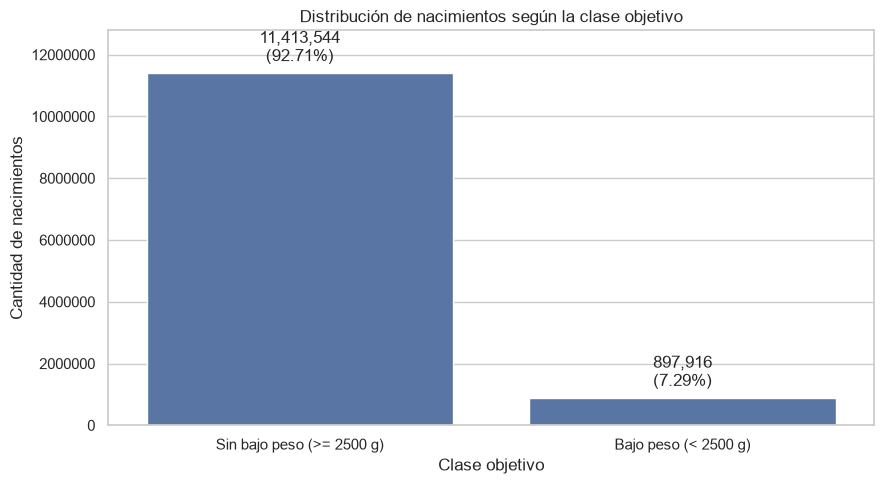

In [24]:
nacimientos_por_clase = (
    df_eda.groupby("bajo_peso")["nacimientos_cantidad"]
    .sum()
    .rename(index={
        0: "Sin bajo peso (>= 2500 g)",
        1: "Bajo peso (< 2500 g)"
    })
)

porcentajes = (
    nacimientos_por_clase
    / nacimientos_por_clase.sum()
    * 100
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=nacimientos_por_clase.index,
    y=nacimientos_por_clase.values
)

for barra, cantidad, porcentaje in zip(
    ax.patches,
    nacimientos_por_clase.values,
    porcentajes.values
):
    ax.annotate(
        f"{cantidad:,.0f}\n({porcentaje:.2f}%)",
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title("Distribución de nacimientos según la clase objetivo")
plt.xlabel("Clase objetivo")
plt.ylabel("Cantidad de nacimientos")
plt.ticklabel_format(axis="y", style="plain")
plt.ylim(0, nacimientos_por_clase.max() * 1.12)
plt.tight_layout()
plt.show()

### 3.3. Evolución anual del bajo peso al nacer

Se analiza la evolución anual del porcentaje de nacimientos con bajo peso durante el período 2005–2022.

Para ello, se agrupan los nacimientos por año y por clase objetivo, utilizando `nacimientos_cantidad` como ponderador. Luego, se calcula el porcentaje de nacimientos con bajo peso sobre el total de nacimientos registrados en cada año.

La visualización permite observar cómo varió la proporción de bajo peso a lo largo del período estudiado, sin atribuir esas variaciones a causas específicas.

In [25]:
evolucion_anual = (
    df_eda.groupby(["anio", "bajo_peso"])["nacimientos_cantidad"]
    .sum()
    .unstack(fill_value=0)
)

porcentaje_bajo_peso = (
    evolucion_anual[1]
    / evolucion_anual.sum(axis=1)
    * 100
)

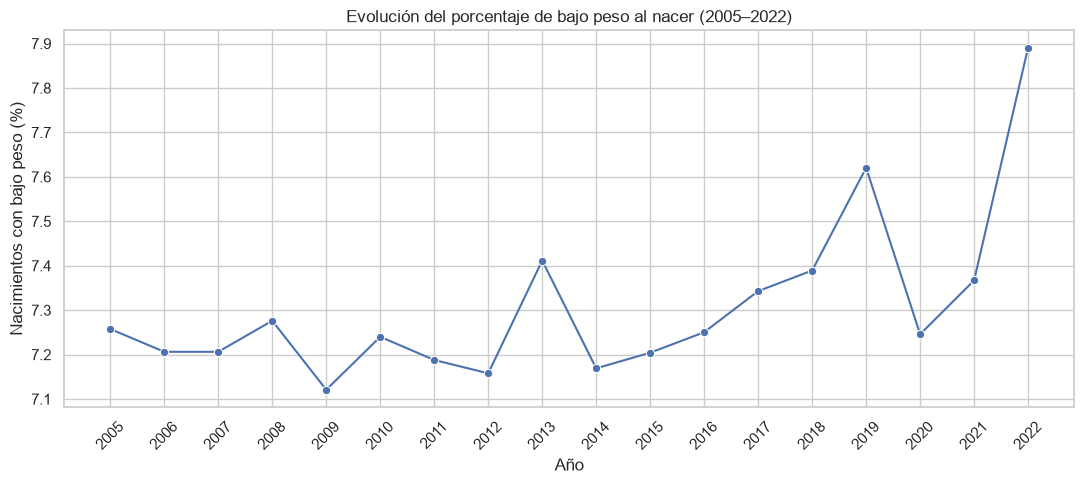

In [26]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    x=porcentaje_bajo_peso.index,
    y=porcentaje_bajo_peso.values,
    marker="o"
)

plt.title("Evolución del porcentaje de bajo peso al nacer (2005–2022)")
plt.xlabel("Año")
plt.ylabel("Nacimientos con bajo peso (%)")
plt.xticks(porcentaje_bajo_peso.index, rotation=45)

plt.tight_layout()
plt.show()

**Interpretación:**

Entre 2005 y 2012, el porcentaje de nacimientos con bajo peso se mantuvo relativamente estable, con valores cercanos al 7,2 %. A partir de 2013 se observan algunas variaciones, destacándose un incremento entre 2017 y 2019, cuando el porcentaje alcanzó el 7,62 %.

En 2020 se registró una disminución al 7,25 %, seguida de nuevos aumentos en 2021 y 2022. Este último año presentó el porcentaje más alto del período analizado, con un 7,89 %.

En general, se observa que la proporción de nacimientos con bajo peso varió a lo largo del período, aunque se mantuvo en torno al 7 % durante la mayor parte de los años.

### 3.4. Distribución del bajo peso al nacer según jurisdicción

Se analiza la proporción de nacimientos con bajo peso en cada jurisdicción de residencia habitual de la madre.

Para realizar la comparación, se agrupan los registros por jurisdicción y clase objetivo, utilizando `nacimientos_cantidad` como ponderador. Luego, se calcula el porcentaje de nacimientos con bajo peso sobre el total de nacimientos correspondiente a cada jurisdicción.

Se incluyen las categorías "Otro país" y "Lugar no especificado", ya que forman parte de los registros originales y fueron conservadas durante la preparación de los datos.

La visualización permite comparar la proporción de bajo peso entre las jurisdicciones, independientemente de la cantidad total de nacimientos que representa cada una.

In [27]:
bajo_peso_jurisdiccion = (
    df_eda.groupby(["jurisdicion_residencia_nombre", "bajo_peso"])
    ["nacimientos_cantidad"]
    .sum()
    .unstack(fill_value=0)
)

porcentaje_bajo_peso_jurisdiccion = (
    bajo_peso_jurisdiccion[1]
    / bajo_peso_jurisdiccion.sum(axis=1)
    * 100
).sort_values(ascending=False)

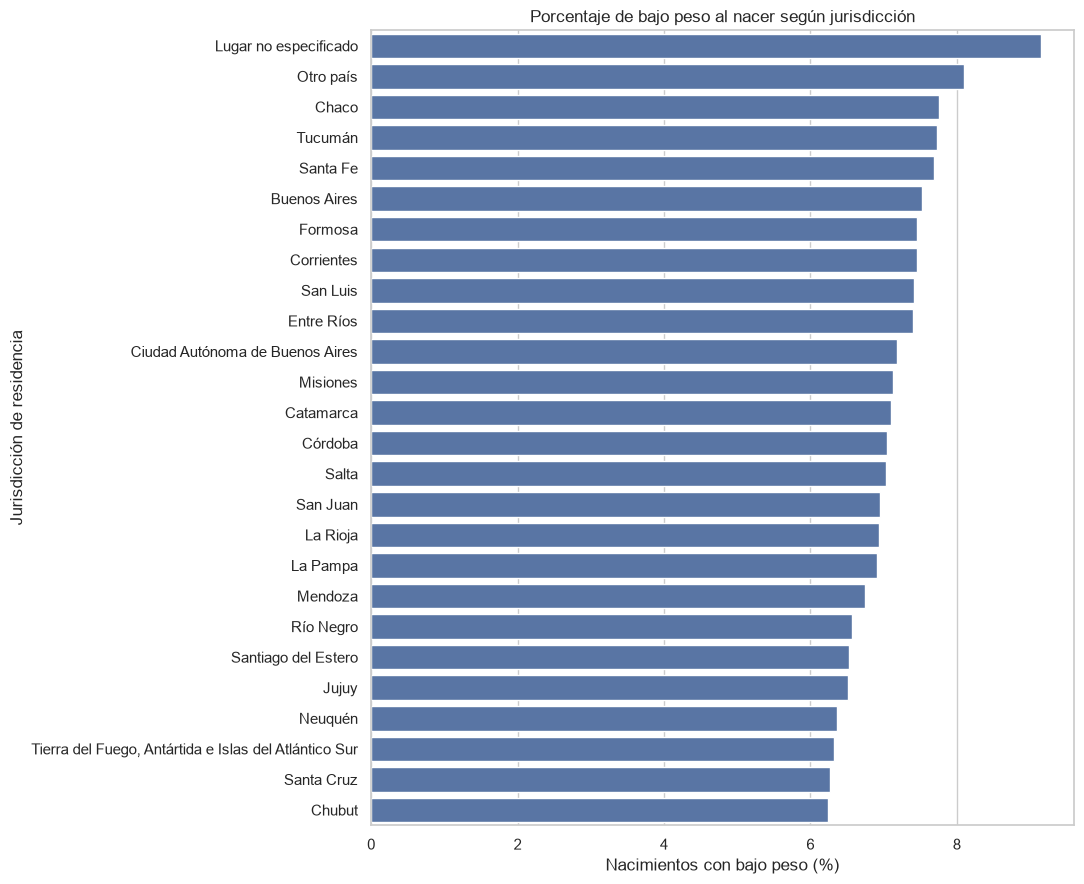

In [28]:
plt.figure(figsize=(11, 9))

sns.barplot(
    x=porcentaje_bajo_peso_jurisdiccion.values,
    y=porcentaje_bajo_peso_jurisdiccion.index
)

plt.title("Porcentaje de bajo peso al nacer según jurisdicción")
plt.xlabel("Nacimientos con bajo peso (%)")
plt.ylabel("Jurisdicción de residencia")

plt.tight_layout()
plt.show()

**Interpretación:**

Se observan diferencias en la proporción de nacimientos con bajo peso entre las distintas jurisdicciones. Entre las jurisdicciones argentinas, Chaco (7,76 %), Tucumán (7,73 %) y Santa Fe (7,69 %) presentan los porcentajes más elevados. Por otro lado, Chubut (6,24 %), Santa Cruz (6,26 %) y Tierra del Fuego (6,32 %) registran los porcentajes más bajos.

Las categorías "Lugar no especificado" (9,14 %) y "Otro país" (8,10 %) también presentan porcentajes elevados. Sin embargo, se consideran por separado, ya que no corresponden a jurisdicciones provinciales identificadas.

En general, los resultados muestran variaciones en la proporción de bajo peso entre las jurisdicciones durante el período analizado, sin que estas diferencias permitan establecer por sí mismas las causas que las originan.

### 3.5. Distribución del bajo peso según edad materna

Se analiza la proporción de nacimientos con bajo peso según los grupos de edad de la madre.

Para ello, se agrupan los registros por intervalo de edad materna y clase objetivo, utilizando `nacimientos_cantidad` como ponderador. Luego, se calcula el porcentaje de nacimientos con bajo peso sobre el total correspondiente a cada grupo.

La visualización permite comparar las proporciones entre los distintos grupos de edad, manteniendo la categoría "Sin especificar" como parte de los datos.

In [29]:
bajo_peso_edad = (
    df_eda.groupby(["edad_madre_grupo", "bajo_peso"])
    ["nacimientos_cantidad"]
    .sum()
    .unstack(fill_value=0)
)
porcentaje_bajo_peso_edad = (
    bajo_peso_edad[1]
    / bajo_peso_edad.sum(axis=1)
    * 100
).sort_values(ascending=False)

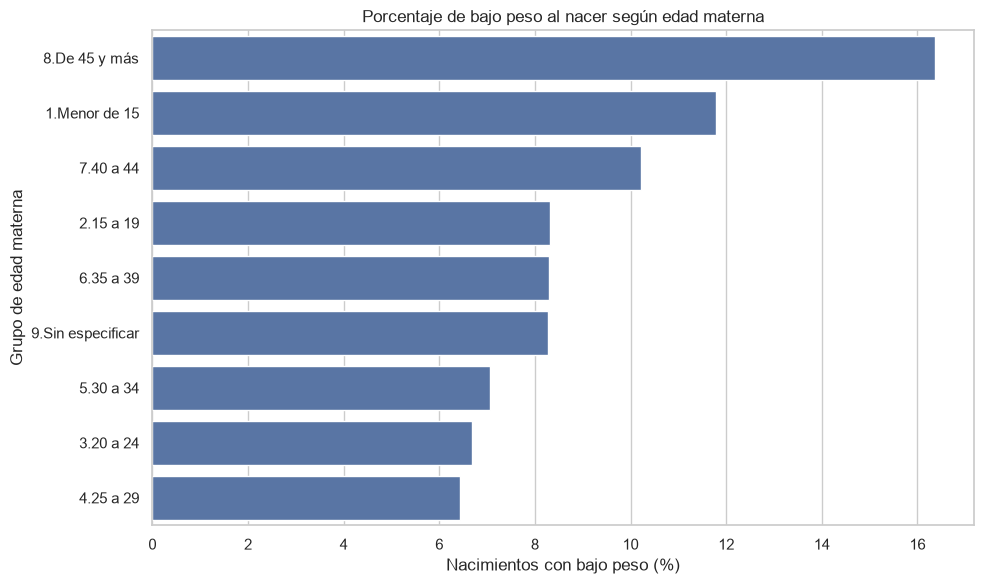

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=porcentaje_bajo_peso_edad.values,
    y=porcentaje_bajo_peso_edad.index
)

plt.title("Porcentaje de bajo peso al nacer según edad materna")
plt.xlabel("Nacimientos con bajo peso (%)")
plt.ylabel("Grupo de edad materna")

plt.tight_layout()
plt.show()

**Interpretación:**

Se observan diferencias en la proporción de nacimientos con bajo peso según el grupo de edad materna. El porcentaje más elevado corresponde al grupo de 45 años y más (16,36 %), seguido por las madres menores de 15 años (11,78 %) y el grupo de 40 a 44 años (10,22 %).

Por otro lado, los porcentajes más bajos se registran en los grupos de 25 a 29 años (6,42 %) y de 20 a 24 años (6,68 %). Los grupos de 15 a 19 años y de 35 a 39 años presentan valores cercanos al 8,3 %.

La categoría "Sin especificar" registra un 8,28 % y se conserva diferenciada de los grupos de edad identificados.

En general, los resultados muestran variaciones en la proporción de bajo peso entre los distintos grupos etarios. Estas diferencias son descriptivas y no permiten establecer por sí mismas una relación causal entre la edad materna y el bajo peso al nacer.

### 3.6. Distribución del bajo peso según nivel de instrucción materna

Se analiza la proporción de nacimientos con bajo peso según el nivel de instrucción de la madre.

Para ello, se agrupan los registros por nivel de instrucción y clase objetivo, utilizando `nacimientos_cantidad` como ponderador. Luego, se calcula el porcentaje de nacimientos con bajo peso sobre el total correspondiente a cada categoría.

La visualización permite comparar las proporciones entre los distintos niveles de instrucción. La categoría "Sin especificar" se conserva como grupo independiente.

In [31]:
bajo_peso_instruccion = (
    df_eda.groupby(["instruccion_madre", "bajo_peso"])
    ["nacimientos_cantidad"]
    .sum()
    .unstack(fill_value=0)
)

porcentaje_bajo_peso_instruccion = (
    bajo_peso_instruccion[1]
    / bajo_peso_instruccion.sum(axis=1)
    * 100
).sort_values(ascending=False)

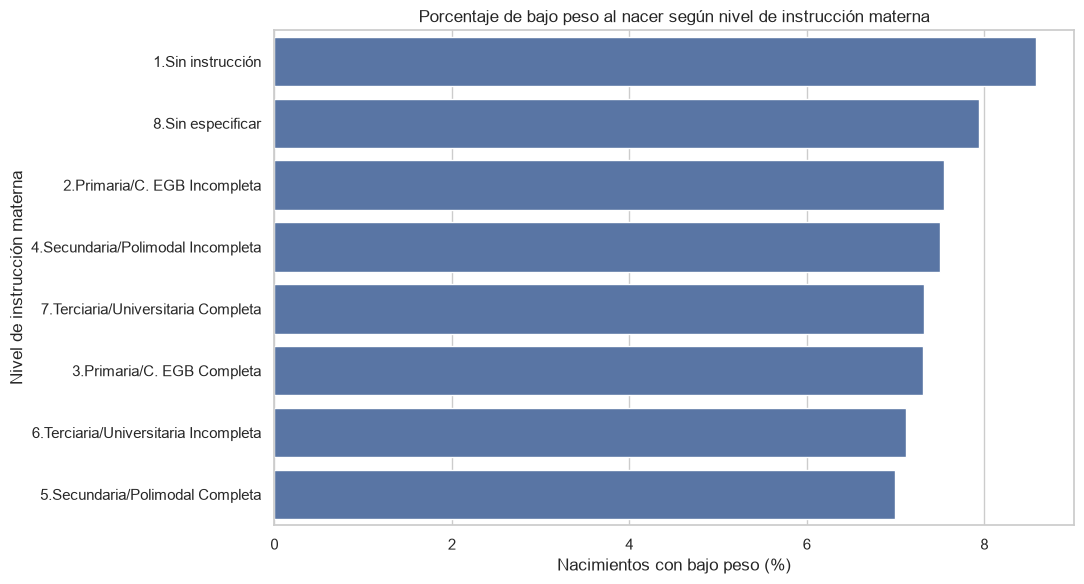

In [32]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=porcentaje_bajo_peso_instruccion.values,
    y=porcentaje_bajo_peso_instruccion.index
)

plt.title("Porcentaje de bajo peso al nacer según nivel de instrucción materna")
plt.xlabel("Nacimientos con bajo peso (%)")
plt.ylabel("Nivel de instrucción materna")

plt.tight_layout()
plt.show()

**Interpretación:**

Se observan diferencias en la proporción de nacimientos con bajo peso según el nivel de instrucción materna. El porcentaje más elevado corresponde a la categoría "Sin instrucción" (8,58 %), mientras que el más bajo se registra en "Secundaria/Polimodal completa" (6,99 %).

Las categorías "Primaria/C. EGB incompleta" (7,55 %) y "Secundaria/Polimodal incompleta" (7,50 %) presentan porcentajes similares. Por su parte, "Sin especificar" registra un 7,94 % y se conserva como categoría independiente.

En general, los porcentajes presentan diferencias moderadas entre los niveles de instrucción analizados. No se observa una progresión uniforme entre las categorías, por lo que estos resultados se interpretan de manera descriptiva y no permiten establecer una relación causal entre el nivel educativo materno y el bajo peso al nacer.

### 3.7. Distribución del bajo peso según tipo de parto

Se analiza la proporción de nacimientos con bajo peso según el tipo de parto registrado.

Para ello, se agrupan los registros por tipo de parto y clase objetivo, utilizando `nacimientos_cantidad` como ponderador. Luego, se calcula el porcentaje de nacimientos con bajo peso sobre el total correspondiente a cada categoría.

La variable distingue entre partos simples y múltiples, además de conservar la categoría "Sin especificar". Esta clasificación no representa la vía de nacimiento (vaginal o cesárea).

In [33]:
bajo_peso_tipo_parto = (
    df_eda.groupby(["tipo_de_parto_nombre", "bajo_peso"])
    ["nacimientos_cantidad"]
    .sum()
    .unstack(fill_value=0)
)

porcentaje_bajo_peso_tipo_parto = (
    bajo_peso_tipo_parto[1]
    / bajo_peso_tipo_parto.sum(axis=1)
    * 100
).sort_values(ascending=False)

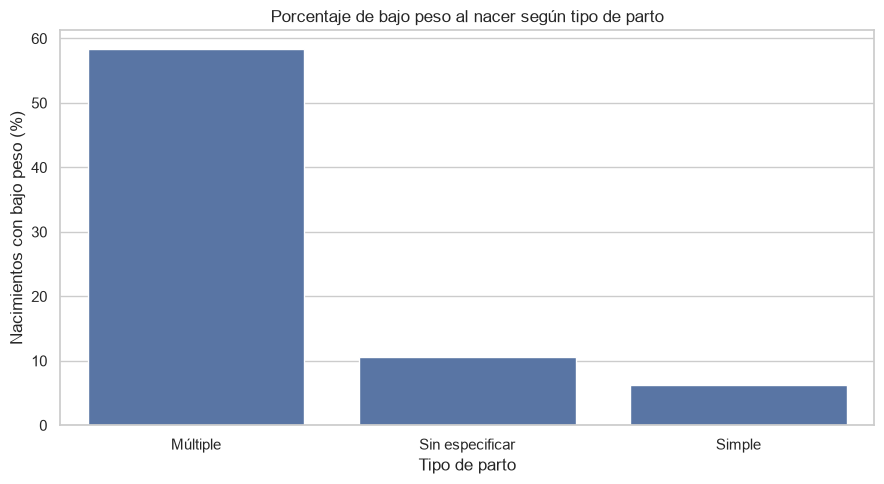

In [34]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=porcentaje_bajo_peso_tipo_parto.index,
    y=porcentaje_bajo_peso_tipo_parto.values
)

plt.title("Porcentaje de bajo peso al nacer según tipo de parto")
plt.xlabel("Tipo de parto")
plt.ylabel("Nacimientos con bajo peso (%)")

plt.tight_layout()
plt.show()

**Interpretación:**

Se observa una diferencia marcada en la proporción de nacimientos con bajo peso según el tipo de parto. La categoría "Múltiple" presenta el porcentaje más elevado, con un 58,33 %, mientras que los partos simples registran un 6,32 %.

Por su parte, la categoría "Sin especificar" presenta un 10,65 % y se mantiene diferenciada de los tipos de parto identificados.

La diferencia entre los partos múltiples y simples es de 52,01 puntos porcentuales. Este resultado muestra una marcada variación en la proporción de bajo peso entre ambas categorías, aunque el análisis descriptivo no permite establecer por sí mismo una relación causal.

### 3.8. Distribución del bajo peso según semanas de gestación

Se analiza la proporción de nacimientos con bajo peso según el intervalo de semanas de gestación registrado.

Para ello, se agrupan los registros por intervalo de gestación y clase objetivo, utilizando `nacimientos_cantidad` como ponderador. Luego, se calcula el porcentaje de nacimientos con bajo peso sobre el total correspondiente a cada intervalo.

La visualización permite comparar las proporciones entre los distintos intervalos de gestación, conservando la categoría "Sin especificar" como grupo independiente.

In [35]:
bajo_peso_gestacion = (
    df_eda.groupby(["semana_gestacion", "bajo_peso"])
    ["nacimientos_cantidad"]
    .sum()
    .unstack(fill_value=0)
)

porcentaje_bajo_peso_gestacion = (
    bajo_peso_gestacion[1]
    / bajo_peso_gestacion.sum(axis=1)
    * 100
).sort_values(ascending=False)

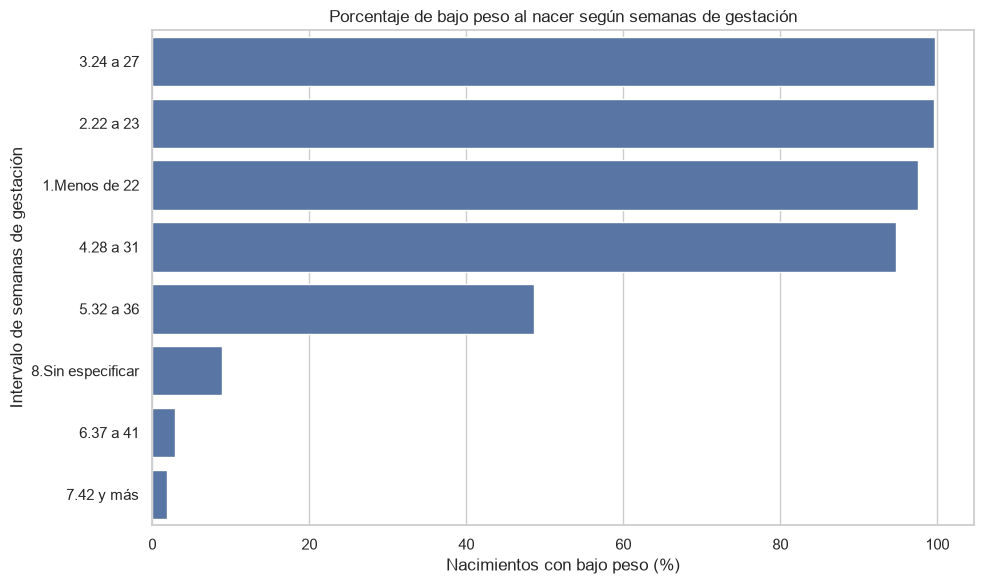

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=porcentaje_bajo_peso_gestacion.values,
    y=porcentaje_bajo_peso_gestacion.index
)

plt.title("Porcentaje de bajo peso al nacer según semanas de gestación")
plt.xlabel("Nacimientos con bajo peso (%)")
plt.ylabel("Intervalo de semanas de gestación")

plt.tight_layout()
plt.show()

**Interpretación:**

Se observan diferencias muy marcadas en la proporción de nacimientos con bajo peso según el intervalo de semanas de gestación.

Los porcentajes más elevados corresponden a los intervalos de 24 a 27 semanas (99,68 %), de 22 a 23 semanas (99,54 %) y de menos de 22 semanas (97,55 %). También se registra un porcentaje elevado en el intervalo de 28 a 31 semanas (94,69 %).

A medida que se consideran intervalos de mayor duración de la gestación, los porcentajes disminuyen. En el grupo de 32 a 36 semanas se registra un 48,64 %, mientras que en el intervalo de 37 a 41 semanas el porcentaje es del 2,86 %. Para los nacimientos de 42 semanas y más, se obtiene un 1,84 %.

La categoría "Sin especificar" presenta un 8,92 % y se conserva como grupo independiente.

En general, los resultados muestran una marcada variación en la proporción de bajo peso entre los intervalos de gestación. Estas diferencias se describen en el contexto del análisis retrospectivo y no representan una predicción prenatal ni permiten establecer por sí solas relaciones causales.

### 3.9. Distribución del bajo peso según sexo

Se analiza la proporción de nacimientos con bajo peso según el sexo registrado.

Para ello, se agrupan los registros por sexo y clase objetivo, utilizando `nacimientos_cantidad` como ponderador. Luego, se calcula el porcentaje de nacimientos con bajo peso sobre el total correspondiente a cada categoría.

La categoría "Sin especificar" se conserva como grupo independiente para mantener la información disponible en los registros.

In [37]:
bajo_peso_sexo = (
    df_eda.groupby(["Sexo", "bajo_peso"])
    ["nacimientos_cantidad"]
    .sum()
    .unstack(fill_value=0)
)

porcentaje_bajo_peso_sexo = (
    bajo_peso_sexo[1]
    / bajo_peso_sexo.sum(axis=1)
    * 100
).sort_values(ascending=False)

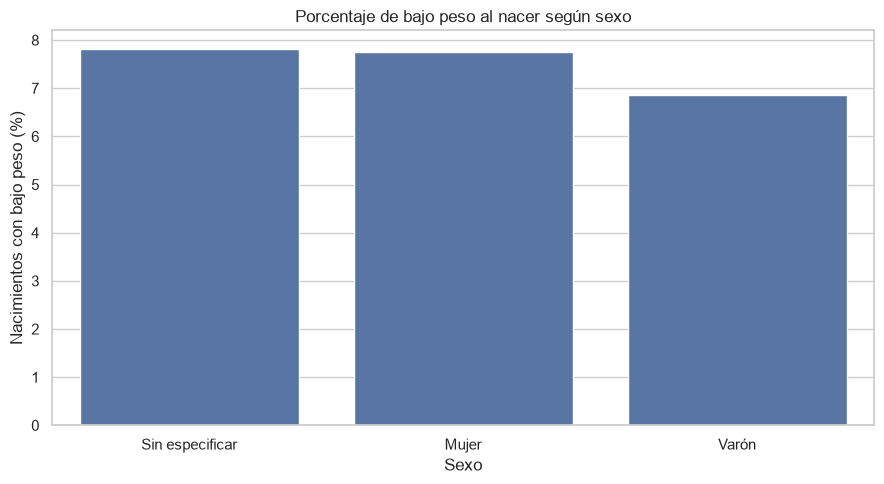

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=porcentaje_bajo_peso_sexo.index,
    y=porcentaje_bajo_peso_sexo.values
)

plt.title("Porcentaje de bajo peso al nacer según sexo")
plt.xlabel("Sexo")
plt.ylabel("Nacimientos con bajo peso (%)")

plt.tight_layout()
plt.show()

**Interpretación:**

Se observan diferencias en la proporción de nacimientos con bajo peso según el sexo registrado. La categoría "Mujer" presenta un porcentaje del 7,75 %, mientras que en "Varón" se registra un 6,86 %. La diferencia entre ambas categorías es de 0,89 puntos porcentuales.

Por su parte, la categoría "Sin especificar" presenta un 7,81 % y se conserva como grupo independiente.

En general, los porcentajes son relativamente próximos entre las categorías analizadas. Estas diferencias se describen de manera exploratoria y no permiten establecer por sí mismas una relación causal.

### 3.10. Conclusiones del análisis exploratorio

El análisis exploratorio permitió caracterizar los registros de nacimientos de Argentina correspondientes al período 2005–2022 e identificar diferencias en la proporción de bajo peso al nacer según distintas características maternas y del nacimiento.

Luego de excluir los registros cuyo peso al nacer no estaba especificado, se trabajó con 520.422 registros agregados, que representan un total de 12.311.460 nacimientos. De este total, 897.916 nacimientos presentaron bajo peso al nacer, lo que representa el 7,29 % de los casos considerados.

En cuanto a la evolución temporal, la proporción de bajo peso se mantuvo relativamente estable durante gran parte del período, con valores cercanos al 7,2 %. Sin embargo, se observaron algunas variaciones, entre ellas un incremento en 2022, cuando alcanzó el 7,89 %.

El análisis de las características maternas y del nacimiento permitió identificar diferencias relevantes entre categorías:

- **Tipo de parto:** los nacimientos múltiples presentaron una proporción de bajo peso del 58,33 %, frente al 6,32 % observado en los nacimientos simples. Esta fue una de las diferencias más marcadas del análisis.
- **Semanas de gestación:** se observó una proporción elevada de bajo peso en los registros correspondientes a gestaciones de menor duración. Por ejemplo, alcanzó el 94,69 % entre las 28 y 31 semanas, mientras que entre las 37 y 41 semanas fue del 2,86 %. Esta variable representa la duración de la gestación registrada al momento del nacimiento.
- **Edad materna:** se identificaron diferencias entre los grupos, con una proporción del 16,36 % en madres de 45 años o más y del 6,42 % en el grupo de 25 a 29 años.
- **Nivel de instrucción materna:** se observaron variaciones entre las categorías, aunque no se identificó un comportamiento progresivo o uniforme entre los distintos niveles educativos.
- **Jurisdicción de residencia:** también se registraron diferencias territoriales. Entre las jurisdicciones argentinas, Chaco presentó una proporción del 7,76 %, mientras que Chubut registró el 6,24 %.
- **Sexo:** la proporción de bajo peso fue del 7,75 % en los registros correspondientes a mujeres y del 6,86 % en los correspondientes a varones.

A partir de estos resultados, se considera pertinente avanzar con la clasificación retrospectiva de los registros utilizando características maternas y del nacimiento. Las variables seleccionadas permiten representar diferentes dimensiones de los datos y explorar su relación con la condición de bajo peso al nacer.

Es importante señalar que las diferencias observadas describen asociaciones dentro de los registros analizados y no permiten establecer relaciones causales. Asimismo, debido al enfoque retrospectivo del proyecto, las semanas de gestación se utilizan como una característica registrada al momento del nacimiento, por lo que el trabajo no constituye una predicción prenatal.

Finalmente, los patrones identificados en esta etapa constituyen un punto de partida para el modelado. La capacidad del modelo Random Forest para clasificar los registros y la persistencia de los patrones observados en períodos posteriores se evaluarán mediante su desempeño sobre el conjunto de prueba correspondiente a los años 2019–2022.

## 4. Preparación para el modelado

### 4.1. Selección de variables

Se definen las variables que se utilizarán durante el proceso de clasificación retrospectiva.

La variable `bajo_peso` se establece como objetivo, mientras que las variables correspondientes a las características maternas y del nacimiento se consideran posibles predictoras.

Se excluyen aquellas variables que no deben intervenir directamente como predictoras:

- `intervalo_peso_al_nacer`: se utilizó para construir la variable objetivo, por lo que su inclusión produciría fuga de información.
- `nacimientos_cantidad`: representa la cantidad de nacimientos correspondiente a cada registro y se conservará como ponderador.
- `anio`: se utilizará para realizar la separación temporal entre los conjuntos de entrenamiento y prueba, pero no como variable predictora.

La selección busca conservar la información pertinente para la clasificación sin incorporar variables que revelen directamente la clase objetivo o que cumplan funciones diferentes a la predicción.

In [39]:
variables_predictoras = [
    "jurisdicion_residencia_nombre",
    "edad_madre_grupo",
    "instruccion_madre",
    "tipo_de_parto_nombre",
    "semana_gestacion",
    "Sexo"
]

variable_objetivo = "bajo_peso"
variable_temporal = "anio"
variable_ponderacion = "nacimientos_cantidad"

In [40]:
columnas_seleccionadas = (
    variables_predictoras
    + [
        variable_objetivo,
        variable_temporal,
        variable_ponderacion
    ]
)

display(df_eda[columnas_seleccionadas].head())

,jurisdicion_residencia_nombre,edad_madre_grupo,instruccion_madre,tipo_de_parto_nombre,semana_gestacion,Sexo,bajo_peso,anio,nacimientos_cantidad
0,Ciudad Autónoma de Buenos Aires,1.Menor de 15,2.Primaria/C. EGB Incompleta,Simple,6.37 a 41,Varón,0,2005,2
1,Ciudad Autónoma de Buenos Aires,1.Menor de 15,2.Primaria/C. EGB Incompleta,Simple,6.37 a 41,Mujer,0,2005,2
2,Ciudad Autónoma de Buenos Aires,1.Menor de 15,2.Primaria/C. EGB Incompleta,Simple,6.37 a 41,Varón,0,2005,3
3,Ciudad Autónoma de Buenos Aires,1.Menor de 15,2.Primaria/C. EGB Incompleta,Simple,6.37 a 41,Mujer,0,2005,1
4,Ciudad Autónoma de Buenos Aires,1.Menor de 15,2.Primaria/C. EGB Incompleta,Simple,7.42 y más,Mujer,0,2005,1


### 4.2. Separación temporal de los conjuntos de entrenamiento y prueba

Se realiza una separación temporal de los registros para evaluar posteriormente los modelos sobre un período diferente al utilizado durante su entrenamiento.

Se establece el período 2005–2018 para el conjunto de entrenamiento y el período 2019–2022 para el conjunto de prueba.

Esta estrategia permite evaluar el comportamiento de los modelos sobre registros correspondientes a años posteriores a los utilizados durante el entrenamiento, respetando el orden temporal de los datos.

La separación se realiza antes de aplicar cualquier procedimiento de preprocesamiento, con el objetivo de evitar la fuga de información entre ambos conjuntos.

In [41]:
df_train = df_eda[
    df_eda["anio"] <= 2018
].copy()

df_test = df_eda[
    df_eda["anio"] >= 2019
].copy()

In [42]:
print("Conjunto de entrenamiento:")
print("Dimensiones:", df_train.shape)
print("Período:", df_train["anio"].min(), "-", df_train["anio"].max())

print("\nConjunto de prueba:")
print("Dimensiones:", df_test.shape)
print("Período:", df_test["anio"].min(), "-", df_test["anio"].max())

Conjunto de entrenamiento:
Dimensiones: (419765, 13)
Período: 2005 - 2018

Conjunto de prueba:
Dimensiones: (100657, 13)
Período: 2019 - 2022


In [43]:
anios_train = set(df_train["anio"].unique())
anios_test = set(df_test["anio"].unique())

print("Años compartidos:", anios_train.intersection(anios_test))

Años compartidos: set()


### 4.3. Separación de variables predictoras, objetivo y ponderador

Se separan las variables de cada conjunto según su función dentro del proceso de clasificación.

Las variables predictoras se almacenan en `X`, mientras que la variable objetivo `bajo_peso` se almacena en `y`.

Por otra parte, `nacimientos_cantidad` se conserva como ponderador, ya que cada registro representa una cantidad determinada de nacimientos y no necesariamente un nacimiento individual.

La variable `anio` se mantiene fuera de las predictoras, debido a que ya fue utilizada para realizar la separación temporal.

In [44]:
X_train = df_train[variables_predictoras].copy()
X_test = df_test[variables_predictoras].copy()

y_train = df_train[variable_objetivo].copy()
y_test = df_test[variable_objetivo].copy()

pesos_train = df_train[variable_ponderacion].copy()
pesos_test = df_test[variable_ponderacion].copy()

In [45]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("pesos_train:", pesos_train.shape)
print("pesos_test:", pesos_test.shape)

X_train: (419765, 6)
X_test: (100657, 6)
y_train: (419765,)
y_test: (100657,)
pesos_train: (419765,)
pesos_test: (100657,)


### 4.4. Identificación de variables categóricas y numéricas

Se identifican los tipos de variables predictoras para definir los procedimientos de preprocesamiento correspondientes.

Las variables seleccionadas son categóricas, por lo que se utilizará One-Hot Encoding para transformarlas en columnas numéricas que puedan ser procesadas por el modelo de clasificación.

Aunque algunas variables representan intervalos ordenados, se mantienen como categóricas para evitar asignarles valores numéricos que impliquen distancias iguales entre categorías.

In [46]:
print("Tipos de datos de las variables predictoras:")
display(X_train.dtypes)

print("\nCantidad de categorías por variable:")
display(X_train.nunique().sort_values(ascending=False))

Tipos de datos de las variables predictoras:


jurisdicion_residencia_nombre    str
edad_madre_grupo                 str
instruccion_madre                str
tipo_de_parto_nombre             str
semana_gestacion                 str
Sexo                             str
dtype: object


Cantidad de categorías por variable:


jurisdicion_residencia_nombre    26
edad_madre_grupo                  9
instruccion_madre                 8
semana_gestacion                  8
tipo_de_parto_nombre              3
Sexo                              3
dtype: int64

### 4.5. Configuración del preprocesamiento

Se configura el procedimiento de transformación de las variables categóricas mediante One-Hot Encoding.

Para organizar el preprocesamiento se utiliza `ColumnTransformer`, que permite aplicar transformaciones específicas a las columnas seleccionadas.

El codificador se ajustará posteriormente utilizando exclusivamente el conjunto de entrenamiento. Se establece `handle_unknown="ignore"` para permitir el procesamiento de categorías que pudieran aparecer en el conjunto de prueba y que no hayan sido observadas durante el entrenamiento.

De esta manera, se evita que la información del conjunto de prueba intervenga en el aprendizaje de las transformaciones.

In [47]:
variables_categoricas = variables_predictoras.copy()

In [48]:
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        )
    ],
    remainder="drop"
)

### 4.6. Ajuste y aplicación del preprocesamiento

Se ajusta el preprocesador utilizando exclusivamente las variables predictoras del conjunto de entrenamiento mediante `fit_transform()`.

Durante este proceso, One-Hot Encoder identifica las categorías presentes en los datos de entrenamiento y genera las columnas binarias correspondientes.

Posteriormente, se utiliza `transform()` para aplicar exactamente las mismas transformaciones al conjunto de prueba, sin volver a ajustar el codificador.

Este procedimiento permite mantener la correspondencia entre las columnas de ambos conjuntos y evitar la fuga de información.

Finalmente, se guarda el preprocesador ajustado mediante la biblioteca `joblib`. Esto permite conservar las categorías y transformaciones aprendidas durante el entrenamiento y reutilizarlas posteriormente sobre nuevos registros, sin necesidad de volver a ajustar el codificador. El archivo se utiliza en el Notebook 02 para transformar los datos sintéticos antes de realizar las predicciones.

In [49]:
X_train_encoded = preprocesador.fit_transform(X_train)

X_test_encoded = preprocesador.transform(X_test)

In [50]:
print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded:", X_test_encoded.shape)

X_train_encoded: (419765, 57)
X_test_encoded: (100657, 57)


In [51]:
ruta_preprocesador = "../data/interim/preprocesador.joblib"

joblib.dump(preprocesador, ruta_preprocesador)

print("Preprocesador guardado correctamente.")

Preprocesador guardado correctamente.


In [52]:
print("Archivo encontrado:", os.path.exists(ruta_preprocesador))
print("Ruta:", ruta_preprocesador)

Archivo encontrado: True
Ruta: ../data/interim/preprocesador.joblib


### 4.7. Validación de las variables transformadas
Se comprueba la cantidad de columnas generadas por el preprocesamiento y se inspeccionan sus nombres para verificar cómo quedaron representadas las categorías de las variables originales.

In [53]:
nombres_columnas = preprocesador.get_feature_names_out()

print("Cantidad de columnas generadas:", len(nombres_columnas))
print("\nPrimeras 15 columnas:")
print(nombres_columnas[:15])

Cantidad de columnas generadas: 57

Primeras 15 columnas:
['categoricas__jurisdicion_residencia_nombre_Buenos Aires'
 'categoricas__jurisdicion_residencia_nombre_Catamarca'
 'categoricas__jurisdicion_residencia_nombre_Chaco'
 'categoricas__jurisdicion_residencia_nombre_Chubut'
 'categoricas__jurisdicion_residencia_nombre_Ciudad Autónoma de Buenos Aires'
 'categoricas__jurisdicion_residencia_nombre_Corrientes'
 'categoricas__jurisdicion_residencia_nombre_Córdoba'
 'categoricas__jurisdicion_residencia_nombre_Entre Ríos'
 'categoricas__jurisdicion_residencia_nombre_Formosa'
 'categoricas__jurisdicion_residencia_nombre_Jujuy'
 'categoricas__jurisdicion_residencia_nombre_La Pampa'
 'categoricas__jurisdicion_residencia_nombre_La Rioja'
 'categoricas__jurisdicion_residencia_nombre_Lugar no especificado'
 'categoricas__jurisdicion_residencia_nombre_Mendoza'
 'categoricas__jurisdicion_residencia_nombre_Misiones']


La validación permitió comprobar que se generaron 57 columnas a partir de las seis variables categóricas seleccionadas. Los nombres de las columnas reflejan las categorías de las variables originales, ahora representadas mediante indicadores binarios.

Además, tanto el conjunto de entrenamiento como el de prueba presentan la misma cantidad de columnas, lo que garantiza una estructura compatible para la etapa posterior de modelado.

### 4.8. Validación de la estructura de los conjuntos

Se verifica que los conjuntos de variables predictoras transformadas, las variables objetivo y los ponderadores tengan la misma cantidad de registros.

Esta comprobación permite asegurar que cada registro conserve su correspondencia entre las variables predictoras, la clase objetivo y la cantidad de nacimientos que representa.

In [54]:
print("ENTRENAMIENTO")
print("Variables predictoras:", X_train_encoded.shape[0])
print("Variable objetivo:", len(y_train))
print("Ponderadores:", len(pesos_train))

print("\nPRUEBA")
print("Variables predictoras:", X_test_encoded.shape[0])
print("Variable objetivo:", len(y_test))
print("Ponderadores:", len(pesos_test))

ENTRENAMIENTO
Variables predictoras: 419765
Variable objetivo: 419765
Ponderadores: 419765

PRUEBA
Variables predictoras: 100657
Variable objetivo: 100657
Ponderadores: 100657


Se verificó que los conjuntos de variables predictoras transformadas, las variables objetivo y los ponderadores tengan la misma cantidad de registros.

En el conjunto de entrenamiento, los tres componentes contienen 419.765 registros, mientras que en el conjunto de prueba contienen 100.657 registros.

Esta comprobación confirma que se mantiene la correspondencia entre las variables predictoras, la clase objetivo y la cantidad de nacimientos representada por cada registro.

### 4.9. Guardado de los conjuntos de datos para el modelado

Una vez finalizadas la exploración, la limpieza y la preparación de los datos, se guardan los conjuntos de entrenamiento y prueba en formato CSV, dentro de la carpeta `data/interim/`.

Se genera un único archivo ZIP que contiene los siguientes archivos:

- `X_train.csv` y `X_test.csv`: contienen las variables predictoras transformadas mediante One-Hot Encoding.
- `y_train.csv` y `y_test.csv`: contienen la variable objetivo `bajo_peso` correspondiente a cada conjunto.
- `pesos_train.csv` y `pesos_test.csv`: contienen la cantidad de nacimientos representados por cada registro, que se utilizará como ponderación durante el entrenamiento y la evaluación.

De esta manera, se conservan los conjuntos preparados para utilizarlos en la siguiente etapa del proyecto, sin necesidad de repetir el preprocesamiento.

**Próxima etapa:** en el notebook `02_modelado_evaluacion.ipynb` se cargarán estos archivos para construir, ajustar y evaluar el modelo de clasificacion Radom Forest

In [55]:
# Carpeta donde se guardarán los archivos
ruta_salida = Path("../data/interim")
ruta_salida.mkdir(parents=True, exist_ok=True)

# Crear un único archivo ZIP
ruta_zip = ruta_salida / "datos_intermedios_modelado.zip"

with zipfile.ZipFile(
    ruta_zip, mode="w", compression=zipfile.ZIP_DEFLATED
) as archivo_zip:

    # Conjuntos que se guardarán
    conjuntos = {
        "X_train.csv": pd.DataFrame(
            X_train_encoded.toarray(),
            columns=nombres_columnas
        ),
        "X_test.csv": pd.DataFrame(
            X_test_encoded.toarray(),
            columns=nombres_columnas
        ),
        "y_train.csv": y_train.to_frame(name="bajo_peso"),
        "y_test.csv": y_test.to_frame(name="bajo_peso"),
        "pesos_train.csv": pesos_train.to_frame(
            name="nacimientos_cantidad"
        ),
        "pesos_test.csv": pesos_test.to_frame(
            name="nacimientos_cantidad"
        ),
        "anio_train.csv": df_train[variable_temporal].to_frame(),
        "anio_test.csv": df_test[variable_temporal].to_frame(),
    }

    for nombre, datos in conjuntos.items():
        archivo_zip.writestr(
            nombre,
            datos.to_csv(index=False)
        )

print("Archivo ZIP creado correctamente.")
print(f"Ubicación: {ruta_zip}")
print(f"Registros de entrenamiento: {X_train_encoded.shape[0]}")
print(f"Registros de prueba: {X_test_encoded.shape[0]}")
print(f"Tamaño del ZIP: {ruta_zip.stat().st_size / (1024**2):.2f} MB")

Archivo ZIP creado correctamente.
Ubicación: ..\data\interim\datos_intermedios_modelado.zip
Registros de entrenamiento: 419765
Registros de prueba: 100657
Tamaño del ZIP: 1.74 MB
